# 12. Street network analysis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/09_analysis.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/09_analysis.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You analyse the driving network of Monaco with `duckosm.analysis`: the numbers of OSMnx, the junctions, the street
directions, the connected parts, the nearest roads of points, a smaller area and random points on the roads. At the
end, OSMnx itself works on the network.

| Call | What it gives |
|---|---|
| `stats()` | size, connectivity and circuity (and density, with an area): the numbers of OSMnx `basic_stats`, in two views |
| `streets_per_node()` | the streets at each node: dead ends, T junctions, crossings |
| `orientation_entropy()`, `plot_orientation()` | the directions of the streets: a grid or not |
| `components()`, `largest_component()` | the connected parts of the network |
| `nearest_nodes()`, `nearest_edges()` | from points (addresses, sensors, GPS) to the network |
| `clip()` | a smaller area of the network |
| `sample_points()` | random points on the roads |
| `to_osmnx()` | the network as an OSMnx graph |

The guide [duckOSM for OSMnx users](../compare/for-osmnx-users.md) gives the duckOSM call for each OSMnx call.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[analysis,viz] @ {nightly_wheel()}"
    %pip install -q osmnx
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
from duckosm import analysis as an    # the module of this notebook
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
drive = net.driving                                   # the driving mode
drive                                                 # the card

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## Statistics: `stats()`

The numbers of OSMnx `basic_stats`, in two views:

| View | Nodes and edges |
|---|---|
| `osmnx` | a node with exactly 2 neighbouring nodes and its roads passing through is not a node: the graph of OSMnx |
| `duckosm` | every row of `driving.nodes` and `driving.edges` |

duckOSM splits a road where another mode connects, where its tags change and where an OSM way ends. These 2-road nodes
count as intersections in the `duckosm` view. Give `area_m2=` (the area in m²) to get the densities too.

In [3]:
s = an.stats(drive)                                      # both views, the keys of OSMnx basic_stats
s.drop(["streets_per_node_counts", "streets_per_node_proportions"])    # the numbers (the two dicts follow)

,osmnx,duckosm
n,843,1768
m,1484,2840
k_avg,3.520759,3.21267
edge_length_total,96058.971143,96207.398536
edge_length_avg,64.729765,33.875845
streets_per_node_avg,2.537367,2.256787
intersection_count,636,1561
street_length_total,65778.865675,65866.686087
street_segment_count,1070,1997
street_length_avg,61.475575,32.982817


In [4]:
s.loc["streets_per_node_counts"].apply(lambda d: dict(list(d.items())[1:]))    # nodes for each count of streets (from 1)

osmnx       {1: 207, 2: 24, 3: 566, 4: 44, 5: 2}
duckosm    {1: 207, 2: 948, 3: 567, 4: 44, 5: 2}
Name: streets_per_node_counts, dtype: object

## Junctions: `streets_per_node()`

The streets at each node of the `duckosm` view. A two-way road counts once: 1 = a dead end, 2 = a road passing through,
3 = a T junction, 4 = a crossing.

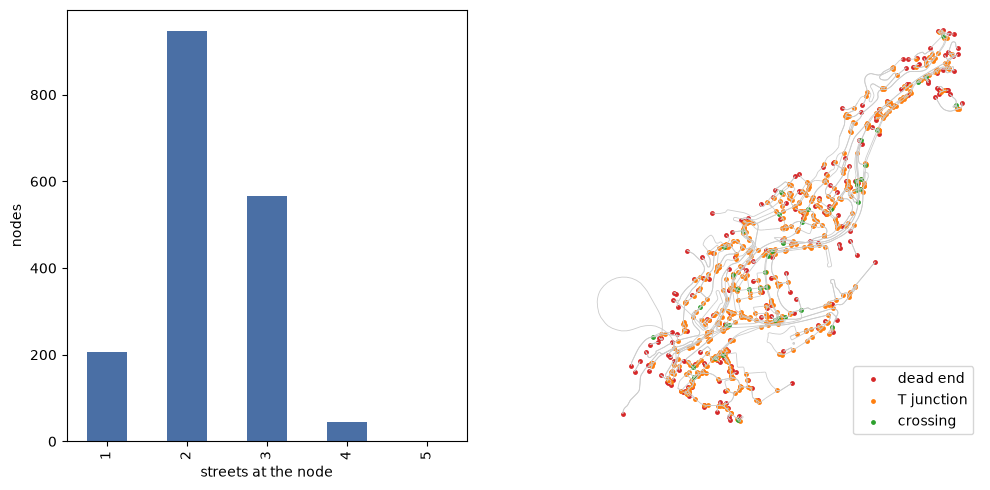

In [5]:
import matplotlib.pyplot as plt

spn = an.streets_per_node(drive)                                             # node_id -> streets
nodes = net.nodes().merge(spn.rename("streets").reset_index(), on="node_id")  # the nodes with their count
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 2]})    # a chart and a map
spn.value_counts().sort_index().plot.bar(ax=a, color="#4a6fa5", xlabel="streets at the node", ylabel="nodes")    # the counts
net.edges().plot(ax=b, color="#cccccc", linewidth=0.6)                       # the roads in gray
for k, color, label in [(1, "#d62728", "dead end"), (3, "#ff7f0e", "T junction"), (4, "#2ca02c", "crossing")]:    # 3 classes
    nodes[nodes.streets == k].plot(ax=b, color=color, markersize=6, label=label)    # the nodes of the class
b.legend(loc="lower right"); b.set_axis_off(); plt.tight_layout(); plt.show()   # the picture

## Street directions: `orientation_entropy()`, `plot_orientation()`

The entropy of the street bearings: 3.58 when the streets go in all directions, 1.39 for a perfect grid. Monaco follows
the coast and the hills: it has no grid.

orientation entropy: 3.528


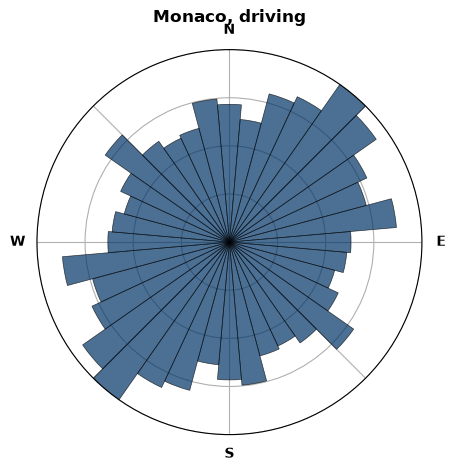

In [6]:
print("orientation entropy:", round(an.orientation_entropy(drive), 3))    # 36 bins of 10 degrees
fig, ax = an.plot_orientation(drive, title="Monaco, driving")          # the polar histogram
plt.show()                                                             # the picture

## Connected parts: `components()`, `largest_component()`

Strongly connected: you can drive from each node of a part to each other node of it. Orange: the edges outside the
largest part, for example a garage ramp that only leaves the network.

122 parts; the largest has 1,600 of 1,768 nodes


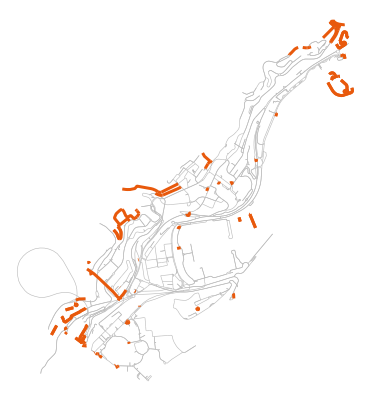

In [7]:
comp = an.components(drive)                                               # node_id -> part (0 = the largest)
print(f"{comp.nunique()} parts; the largest has {(comp == 0).sum():,} of {len(comp):,} nodes")    # the sizes
big = an.largest_component(drive, out="data/monaco_largest.duckdb")       # a new network file with the largest part
edges = net.edges()                                                       # all edges
net.plot(highlight=edges.edge_id[~edges.edge_id.isin(big.edges().edge_id)])    # the edges outside the largest part

## From points to the network: `nearest_nodes()`, `nearest_edges()`

Ten random points (black) and the edge of each one (orange). Arrays in, arrays out; the distances are in metres.

{'edge_id': array([1754122589688343229, 2179780264819535765, 3363728794791538739]), 'distance_m': array([374.9, 618.3,  12.1]), 'node_id': array([   25212793, 12136114443,  1784107000])}


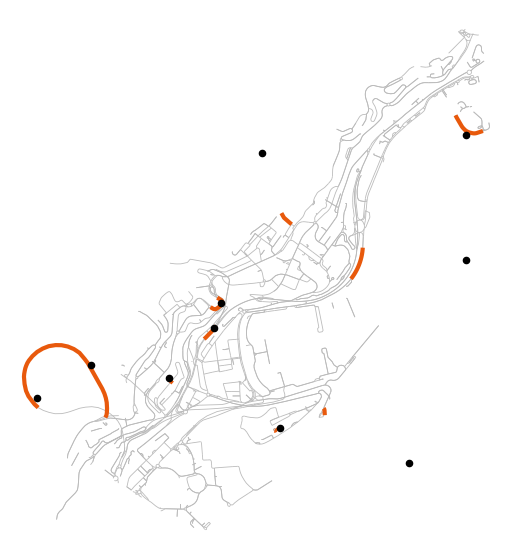

In [8]:
import numpy as np

rng = np.random.default_rng(1)                                    # random points that do not change
w, south, e, north = net.edges().total_bounds                     # the box of the network
xs, ys = rng.uniform(w, e, 10), rng.uniform(south, north, 10)     # 10 points (lon, lat)
ids, dist = an.nearest_edges(drive, xs, ys, return_dist=True)     # the nearest edge of each point
node_ids = an.nearest_nodes(drive, xs, ys)                        # the nearest node of each point
print({"edge_id": ids[:3], "distance_m": dist[:3].round(1), "node_id": node_ids[:3]})    # the first three
ax = plt.subplots(figsize=(7, 7))[1]                              # a new picture
net.plot(highlight=ids, ax=ax)                                    # the edges of the points in orange
ax.scatter(xs, ys, color="black", s=20, zorder=3); plt.show()     # the points

## A smaller area: `clip()`

The network inside 500 m of the Casino square. The result is a new network file; an edge that crosses the circle stays
whole.

702 of 2840 edges


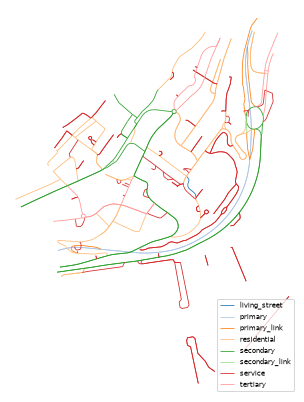

In [9]:
small = an.clip(net, point=(7.4280, 43.7393), dist_m=500, out="data/monaco_casino.duckdb")    # a new network file
print(len(small.edges()), "of", len(net.edges()), "edges")      # the size
small.plot()                                                    # its roads by class

## Random points on the roads: `sample_points()`

200 points; a longer road gets more points. Each point has the `edge_id` of its road.

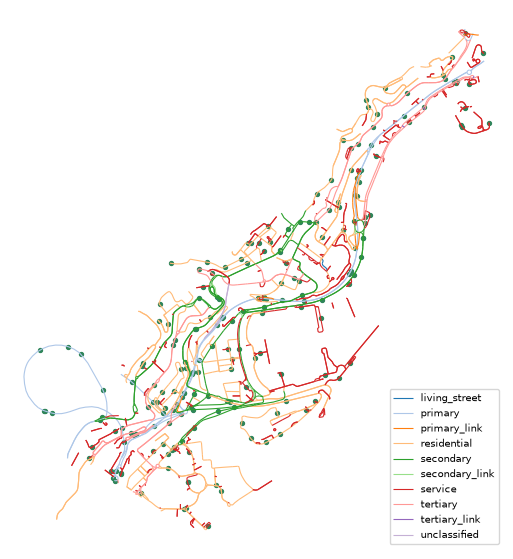

In [10]:
pts = an.sample_points(drive, 200, seed=1)                  # a GeoDataFrame of points with edge_id
ax = plt.subplots(figsize=(7, 7))[1]                         # a new picture
net.plot(ax=ax)                                              # the roads
pts.plot(ax=ax, color="#2f855a", markersize=8); plt.show()   # the points

## Grades: `add_elevation()`, `grades()`

`an.add_elevation(net, dem="dtm.tif")` adds the ground height of a DEM file (GeoTIFF) to the nodes and the edges. Then
`an.grades(drive)` gives `(z_to - z_from) / length_m` for each `edge_id`. This notebook has no DEM file, so it does not
run these calls. See [Add elevation](../guides/elevation.md).

## OSMnx on the network: `to_osmnx()`

The network as the graph of OSMnx. Each OSMnx function works on it, and each edge keeps its `edge_id`. Here OSMnx
finds a route on the largest part (`big`, above) with its own `shortest_path` and draws it.

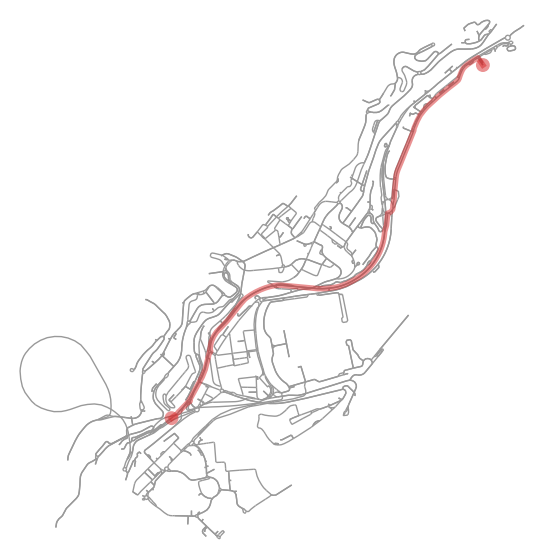

In [11]:
import osmnx as ox

G = an.to_osmnx(big.driving)                                                 # the largest part as a networkx MultiDiGraph
orig, dest = an.nearest_nodes(big.driving, [7.4155, 7.4370], [43.7310, 43.7480])  # two nodes (duckOSM finds them)
route = ox.routing.shortest_path(G, orig, dest, weight="travel_time")        # OSMnx's route
fig, ax = ox.plot.plot_graph_route(G, route, route_color="#d62728", node_size=0, bgcolor="white",
                                   edge_color="#999999", figsize=(7, 7))    # OSMnx's picture